# Climate Comfort Index: multi-horizon GRU experiment

Student **25945320**. Forecasts CCI at **+1, +2 and +3 days** from 14-day weather sequences,
using the chronological splits built by the CCI preprocessing notebook.

Trained on the **training split**, selected and reported on the **validation split**. The 2025
test split is not loaded, not scaled and not scored. Splits are never shuffled, and all scaling
is fitted on training data only.

## Hypothesis

A recurrent encoder reading raw 14-day weather sequences will improve on a persistence forecast
at all three horizons, because the sequence carries trend and volatility information that a
single day's observation does not.

The competing possibility is stated explicitly: with roughly 2,900 training windows and a
persistence correlation that falls to about 0.27 by *t*+3, the network may have too little data
to learn temporal structure that the engineered lag and rolling features already summarise for
the tree models. Both outcomes are reported.

## Design

| Choice | Value | Reason |
|---|---|---|
| Targets | `cci_t1`, `cci_t2`, `cci_t3` | The endpoint returns three days; all three are produced by one model |
| Head | `Linear(hidden, 3)` — one shared encoder, three outputs | See "One encoder, three heads" below |
| Learning target | `cci_th - cci`, standardised per horizon | See "Predicting the residual" below |
| Inputs | 14-day sequences of same-day weather, CCI and day-of-year harmonics | The network should learn temporal structure itself; the precomputed lag and rolling columns are deliberately withheld |
| Network | GRU({HIDDEN_SIZE}) → Dropout → Linear(3) | Small: 2,889 windows will not support a large recurrent net |
| Loss | Huber (`SmoothL1`) on the scaled residuals, averaged over horizons | Gradients scale with error near the optimum; robust to outliers in the tails |
| Metrics | MAE, RMSE, R², prediction spread — per horizon, on the 0–100 CCI scale | Directly comparable with the tree notebooks |
| Baselines | Persistence and a constant prediction | Beating persistence is the minimum bar; the constant is the collapse signature |

## One encoder, three heads

Three predictions can be produced either by training three separate networks or by giving one
network a three-unit output layer. The second is used here.

The encoder learns a representation of "what the last fortnight of weather looks like", and that
representation is equally relevant to all three horizons. Sharing it means the fortnight's
structure is learned from three times as many error signals, which matters when training data is
this limited. Three separate networks would each have to learn the same encoding from scratch on
the same 2,889 windows.

The cost is that one encoder must serve three horizons with different signal-to-noise ratios,
and the shared weights cannot specialise. This is the opposite trade-off to the tree notebooks,
where a separate model per horizon is used precisely because trees cannot share structure. The
comparison between the two approaches is itself a result worth reporting.

## Predicting the residual

Each output is trained on `cci_th - cci`: the amount by which the horizon differs from today's
index, standardised per horizon.

Residuals are standardised **separately for each horizon** because their spreads differ
substantially — persistence is far more accurate at *t*+1 than at *t*+3, so the *t*+1 residual is
much narrower. A single shared scaler would leave two of the three horizons badly conditioned.

The framing does two things. It removes the large offset from the learning target, so the network
begins at the correct intercept instead of spending its training budget climbing to 70. And it
changes the task: rather than re-deriving a persistence forecast it already receives as an input,
the network must learn only what persistence misses. A model that learns nothing now outputs zero
and reproduces persistence, so the failure mode is a sensible fallback rather than a flat line.

## Fixes carried over from the first single-horizon run

The original notebook produced a flat prediction of about 69.5 for every day. That was not
convergence: it is the MAE of the best possible constant prediction when the target has a mean
near 70. The cause was an unscaled target combined with an L1 loss, which has a gradient of ±1
regardless of the size of the error, so the whole run was consumed correcting the intercept.
Points marked **FIX** below are the changes that address it.


In [19]:
from __future__ import annotations

import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

RANDOM_STATE = 25945320
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


def project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "comfort_climate"
MODEL_DIR = PROJECT_ROOT / "models" / "comfort_climate" / "experiments"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "comfort_climate"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

METADATA = json.loads((DATA_DIR / "cci_feature_metadata.json").read_text())

EXPERIMENT = "cci_gru_multihorizon"
ARCHITECTURE = "GRU"
MODEL_LABEL = "gru"

# FIX: all three horizons, not just cci_t3. The prediction endpoint returns three days.
HORIZONS = METADATA["horizons_days"]
TARGET_COLUMNS = [f"cci_t{h}" for h in HORIZONS]
PERSISTENCE_COLUMN = "cci"

# Raw sequence inputs only. The engineered lag and rolling columns are withheld deliberately:
# the point of a recurrent model is to learn that structure from the sequence itself, and
# supplying both would make the comparison with the tree models uninterpretable.
SEQUENCE_FEATURES = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "cloud_cover",
    "precipitation",
    "wind_gusts_10m",
    "cci",
    "doy_sin",
    "doy_cos",
]
LOOKBACK = 14

HIDDEN_SIZE = 32
DROPOUT = 0.2
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

# FIX: the first run stopped during the intercept-climb plateau at epoch 35. A minimum epoch
# count and a longer patience prevent a transient flat region from ending training early.
MAX_EPOCHS = 300
MIN_EPOCHS = 30
PATIENCE = 25
MIN_DELTA = 1e-4

DEVICE = torch.device("cpu")

print(f"PyTorch {torch.__version__} on {DEVICE}")
print(f"Architecture: {ARCHITECTURE}({HIDDEN_SIZE}) with a {len(HORIZONS)}-unit head")
print(f"Targets: {', '.join(TARGET_COLUMNS)} (learned as residuals against "
      f"{PERSISTENCE_COLUMN})")
print(f"Sequence features ({len(SEQUENCE_FEATURES)}): {', '.join(SEQUENCE_FEATURES)}")
print(f"Lookback: {LOOKBACK} days")


PyTorch 2.14.0 on cpu
Architecture: GRU(32) with a 3-unit head
Targets: cci_t1, cci_t2, cci_t3 (learned as residuals against cci)
Sequence features (9): temperature_2m, relative_humidity_2m, wind_speed_10m, cloud_cover, precipitation, wind_gusts_10m, cci, doy_sin, doy_cos
Lookback: 14 days


## 1. Load chronological splits

Only the training and validation files are read; `sydney_cci_test.csv` is left unread. The
preprocessing notebook already applied the warm-up filter and the 3-day embargo at each split
boundary.

A combined history frame is kept so that a window beginning in December 2023 can supply context
for a January 2024 feature date. That is not leakage: those December days would already have
been observed by the time the January date arrives. A window's split membership is determined
solely by its feature date *t*.


In [20]:
def load_split(name: str) -> pd.DataFrame:
    """Read one chronological split and verify it carries the columns this notebook needs."""
    path = DATA_DIR / f"sydney_cci_{name}.csv"
    frame = (
        pd.read_csv(path, parse_dates=["feature_date"])
        .set_index("feature_date")
        .sort_index()
    )
    required = [*SEQUENCE_FEATURES, *TARGET_COLUMNS, PERSISTENCE_COLUMN]
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise ValueError(f"{path.name} is missing required columns: {missing}")
    return frame


splits = {name: load_split(name) for name in ("train", "val")}
history = pd.concat(splits.values()).sort_index()
if history.index.has_duplicates:
    raise ValueError("Split files overlap; sequence windows would mix labels across splits.")

for name, frame in splits.items():
    means = ", ".join(f"{target}={frame[target].mean():.1f}" for target in TARGET_COLUMNS)
    print(f"{name:5} {len(frame):5,} rows  {frame.index.min():%Y-%m-%d} to "
          f"{frame.index.max():%Y-%m-%d}  mean {means}")
print("\nTest split deliberately not loaded.")


train 2,889 rows  2016-01-31 to 2023-12-28  mean cci_t1=71.3, cci_t2=71.3, cci_t3=71.3
val     363 rows  2024-01-01 to 2024-12-28  mean cci_t1=69.6, cci_t2=69.6, cci_t3=69.7

Test split deliberately not loaded.


## 2. Sequence windows

For a feature date *t*, the input is the 14 consecutive calendar days ending on *t*. Windows are
built by calendar date rather than row position, so the 3-day embargo gap between splits is never
mistaken for consecutive weather. Any window with a missing day is dropped rather than filled.

**FIX.** Each window now carries a 3-vector of targets — `cci_t1`, `cci_t2`, `cci_t3` — instead of
a single value. The persistence reference is the same-day CCI and is shared across all three
horizons.

The retention rate is reported. A large shortfall would indicate the calendar-window requirement
is discarding more data than expected, which would be a data problem rather than a modelling one.


In [21]:
def make_windows(
    split: pd.DataFrame, history_frame: pd.DataFrame, lookback: int
) -> tuple[np.ndarray, np.ndarray, np.ndarray, pd.DatetimeIndex]:
    """Build complete calendar lookback windows for one split.

    Parameters
    ----------
    split
        The split whose feature dates define which windows are produced.
    history_frame
        Combined history used only to supply lookback context.
    lookback
        Number of consecutive calendar days in each window, ending on the feature date.

    Returns
    -------
    tuple
        Sequences of shape ``(n, lookback, n_features)``, targets of shape
        ``(n, n_horizons)``, the same-day ``cci`` persistence reference, and the feature dates,
        all in matching order.
    """
    features, targets, persistence, dates = [], [], [], []
    for date in split.index:
        window_index = pd.date_range(date - pd.Timedelta(days=lookback - 1), date, freq="D")
        if not window_index.isin(history_frame.index).all():
            continue
        window = history_frame.loc[window_index, SEQUENCE_FEATURES]
        horizon_values = split.loc[date, TARGET_COLUMNS]
        if window.isna().any().any() or horizon_values.isna().any():
            continue
        features.append(window.to_numpy(dtype=np.float32))
        targets.append(horizon_values.to_numpy(dtype=np.float32))
        persistence.append(np.float32(split.loc[date, PERSISTENCE_COLUMN]))
        dates.append(date)
    if not features:
        raise ValueError("No complete lookback windows were produced.")
    return (
        np.stack(features),
        np.stack(targets),
        np.asarray(persistence, dtype=np.float32),
        pd.DatetimeIndex(dates, name="feature_date"),
    )


raw_windows = {name: make_windows(frame, history, LOOKBACK) for name, frame in splits.items()}
for name, (x, y, _, dates) in raw_windows.items():
    print(f"{name:5} windows: {len(y):5,} of {len(splits[name]):5,} rows "
          f"({len(y) / len(splits[name]):.1%})  x{x.shape}  y{y.shape}  "
          f"{dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}")


train windows: 2,876 of 2,889 rows (99.6%)  x(2876, 14, 9)  y(2876, 3)  2016-02-13 to 2023-12-28
val   windows:   350 of   363 rows (96.4%)  x(350, 14, 9)  y(350, 3)  2024-01-14 to 2024-12-28


## 3. Train-only scaling

**FIX.** The first version scaled the inputs but left the target on the raw 0–100 scale. Combined
with an L1 loss that was the direct cause of the constant-prediction collapse.

Two scalers, both fitted on training data only:

- an **input scaler** over the flattened training windows, applied unchanged to validation;
- a **target scaler** over the training residual matrix `cci_th - cci`, with one column per
  horizon. `StandardScaler` standardises each column independently, which is exactly what is
  needed: the *t*+1 residual is much narrower than the *t*+3 residual, and a shared scale would
  leave two horizons poorly conditioned.

Every reported metric is computed after inverting both the scaling and the residual framing, so
all numbers are on the original 0–100 CCI scale and comparable with the tree notebooks.


In [22]:
train_x, train_y, train_persistence, train_dates = raw_windows["train"]

input_scaler = StandardScaler().fit(train_x.reshape(-1, train_x.shape[-1]))


def scale_windows(windows: np.ndarray) -> np.ndarray:
    """Apply the train-fitted input scaler to a stack of sequence windows."""
    n_steps, n_features = windows.shape[1], windows.shape[2]
    scaled = input_scaler.transform(windows.reshape(-1, n_features))
    return scaled.reshape(-1, n_steps, n_features).astype(np.float32)


# FIX: the network learns the persistence residual per horizon, not the level.
train_residual = train_y - train_persistence[:, None]
target_scaler = StandardScaler().fit(train_residual)


def to_learning_target(y: np.ndarray, persistence: np.ndarray) -> np.ndarray:
    """Convert observed CCI targets into the scaled residuals the network is trained on."""
    return target_scaler.transform(y - persistence[:, None]).astype(np.float32)


def to_cci(scaled_residual: np.ndarray, persistence: np.ndarray) -> np.ndarray:
    """Invert the residual framing and scaling, returning values on the 0-100 CCI scale."""
    residual = target_scaler.inverse_transform(scaled_residual)
    return residual + persistence[:, None]


prepared = {
    name: {
        "x": scale_windows(x),
        "y_scaled": to_learning_target(y, persistence),
        "y_cci": y,
        "persistence": persistence,
        "dates": dates,
    }
    for name, (x, y, persistence, dates) in raw_windows.items()
}


def as_loader(name: str, shuffle: bool) -> DataLoader:
    """Wrap a prepared split in a DataLoader over (sequence, scaled residual vector) pairs."""
    part = prepared[name]
    dataset = TensorDataset(torch.from_numpy(part["x"]), torch.from_numpy(part["y_scaled"]))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)


train_loader = as_loader("train", shuffle=True)
# FIX: a separate unshuffled loader for scoring. The first version evaluated the training split
# through the shuffled loader, comparing predictions against targets in a different order, which
# made the training metrics meaningless.
train_eval_loader = as_loader("train", shuffle=False)
val_loader = as_loader("val", shuffle=False)

residual_summary = pd.DataFrame(
    {
        "residual_mean": train_residual.mean(axis=0),
        "residual_std": train_residual.std(axis=0),
        "raw_target_mean": train_y.mean(axis=0),
        "raw_target_std": train_y.std(axis=0),
    },
    index=TARGET_COLUMNS,
)
print(f"Input scaler fitted on {train_x.shape[0] * LOOKBACK:,} training timesteps.\n")
print("Residual spread widens with horizon, which is why each is standardised separately:\n")
print(residual_summary.to_string())


Input scaler fitted on 40,264 training timesteps.

Residual spread widens with horizon, which is why each is standardised separately:

        residual_mean  residual_std  raw_target_mean  raw_target_std
cci_t1         -0.011         9.286           71.259          10.255
cci_t2         -0.011        11.549           71.259          10.254
cci_t3         -0.013        12.379           71.257          10.254


### What a collapsed model would score

The scores of a model that learns nothing are computed before training, for each horizon:

- the **constant-prediction floor** — always predicting the training median. The original
  single-horizon run landed here;
- the **persistence floor** — carrying today's CCI forward. Under the residual framing this is
  what a model outputting zero would score.

These are drawn as reference lines on the training curves, so a collapse is visible while the
model is still training rather than only in the final table.


In [23]:
val_y_cci = prepared["val"]["y_cci"]
val_persistence = prepared["val"]["persistence"]

constant_prediction = {
    target: float(np.median(train_y[:, index])) for index, target in enumerate(TARGET_COLUMNS)
}
floors = pd.DataFrame(
    {
        "constant_value": [constant_prediction[t] for t in TARGET_COLUMNS],
        "collapse_floor_mae": [
            float(np.abs(val_y_cci[:, i] - constant_prediction[t]).mean())
            for i, t in enumerate(TARGET_COLUMNS)
        ],
        "persistence_floor_mae": [
            float(np.abs(val_y_cci[:, i] - val_persistence).mean())
            for i in range(len(TARGET_COLUMNS))
        ],
    },
    index=TARGET_COLUMNS,
)
print("Validation floors per horizon:\n")
print(floors.to_string())
print("\nA result near collapse_floor_mae means the model has learned only an intercept.")
print("A result worse than persistence_floor_mae means persistence should be deployed instead.")


Validation floors per horizon:

        constant_value  collapse_floor_mae  persistence_floor_mae
cci_t1          72.488               9.075                  7.603
cci_t2          72.488               9.044                  8.624
cci_t3          72.488               9.062                  9.265

A result near collapse_floor_mae means the model has learned only an intercept.
A result worse than persistence_floor_mae means persistence should be deployed instead.


## 4. Model

A single-layer GRU reads the 14-day window; the final hidden state passes through dropout to a
three-unit linear head, one unit per horizon. The GRU merges the forget and input gates and carries no separate cell state, so it has roughly a quarter fewer parameters than an equivalent LSTM. On short sequences and small samples that reduced capacity is often an advantage rather than a limitation.

**FIX.** The head bias is initialised at zero. Under standardised residual targets zero is
already the correct mean, so the network starts at the right intercept rather than climbing to
it.

**FIX.** The loss is Huber rather than MAE. Huber is quadratic within one unit of the optimum, so
gradients shrink as predictions approach the target and the optimiser converges; beyond that it
is linear and tolerant of outliers. Plain MAE has a constant gradient magnitude everywhere, which
is what made the original run so slow to move. The loss is averaged across the three horizons,
which weights them equally — reasonable here because all three residuals were standardised to
unit variance, so no horizon can dominate through scale alone.


In [24]:
class CciGRU(nn.Module):
    """Single-layer GRU encoder with one output unit per forecast horizon."""

    def __init__(self, n_features: int, hidden_size: int, dropout: float,
                 n_horizons: int) -> None:
        super().__init__()
        self.encoder = nn.GRU(input_size=n_features, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, n_horizons)
        # FIX: zero is the mean of every standardised residual column, so the model begins at
        # the correct intercept for all three horizons.
        nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output, _ = self.encoder(x)
        return self.head(self.dropout(output[:, -1, :]))


def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer | None = None,
) -> float:
    """Run one pass over ``loader``, training if an optimiser is supplied. Returns mean loss."""
    training = optimizer is not None
    model.train(training)
    total_loss, n_rows = 0.0, 0
    with torch.set_grad_enabled(training):
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            if training:
                optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(batch_y)
            n_rows += len(batch_y)
    return total_loss / n_rows


example = CciGRU(len(SEQUENCE_FEATURES), HIDDEN_SIZE, DROPOUT, len(HORIZONS))
n_parameters = sum(p.numel() for p in example.parameters())
print(example)
print(f"\nTrainable parameters: {n_parameters:,} for {len(prepared['train']['y_cci']):,} "
      f"training windows")


CciGRU(
  (encoder): GRU(9, 32, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=32, out_features=3, bias=True)
)

Trainable parameters: 4,227 for 2,876 training windows


### Plumbing check: can the model overfit a small subset?

Before the real run the network is trained on 100 windows with dropout disabled. A correctly
wired model should drive the loss on 100 examples close to zero — memorisation is the desired
outcome here.

If it cannot, the fault is in the data path — misaligned sequences and labels, constant inputs, a
scaling error — and no change to architecture or learning rate will help. This check takes
seconds and separates a plumbing bug from a genuine absence of signal, a distinction the original
notebook could not make.


In [25]:
subset_size = 100
subset = TensorDataset(
    torch.from_numpy(prepared["train"]["x"][:subset_size]),
    torch.from_numpy(prepared["train"]["y_scaled"][:subset_size]),
)
subset_loader = DataLoader(subset, batch_size=subset_size, shuffle=False)

probe = CciGRU(len(SEQUENCE_FEATURES), HIDDEN_SIZE, 0.0, len(HORIZONS)).to(DEVICE)
probe_optimizer = torch.optim.Adam(probe.parameters(), lr=1e-2)
probe_criterion = nn.SmoothL1Loss()

first_loss = run_epoch(probe, subset_loader, probe_criterion, probe_optimizer)
for _ in range(300):
    last_loss = run_epoch(probe, subset_loader, probe_criterion, probe_optimizer)

print(f"Overfit probe on {subset_size} windows: loss {first_loss:.4f} -> {last_loss:.4f}")
if last_loss > 0.05:
    print("WARNING: the model cannot memorise 100 examples. Investigate the data path before "
          "interpreting any result below.")
else:
    print("Data path is sound: the network can fit the inputs it is given.")
del probe, probe_optimizer


Overfit probe on 100 windows: loss 0.3469 -> 0.0003
Data path is sound: the network can fit the inputs it is given.


## 5. Training

Early stopping watches validation loss and restores the best weights.

**FIX.** Stopping is not permitted before `MIN_EPOCHS`, and patience is raised from 10 to 25. In
the original run the loss plateaued while the network was still correcting its intercept; the
counter filled during that plateau and training ended before any real learning had begun.

Validation MAE is tracked per horizon in CCI units alongside the loss, so the curves can be read
directly against the floors computed above.


In [26]:
model = CciGRU(len(SEQUENCE_FEATURES), HIDDEN_SIZE, DROPOUT, len(HORIZONS)).to(DEVICE)
criterion = nn.SmoothL1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


@torch.no_grad()
def predict_cci(loader: DataLoader, name: str) -> np.ndarray:
    """Predict on a split, returning an (n, n_horizons) array on the 0-100 CCI scale."""
    model.eval()
    scaled_residuals = np.concatenate(
        [model(batch_x.to(DEVICE)).cpu().numpy() for batch_x, _ in loader]
    )
    return to_cci(scaled_residuals, prepared[name]["persistence"])


curves = {"train_loss": [], "val_loss": [],
          **{f"val_mae_{target}": [] for target in TARGET_COLUMNS}}
best_state, best_val, stale_epochs = None, float("inf"), 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, criterion, optimizer)
    val_loss = run_epoch(model, val_loader, criterion)
    val_prediction = predict_cci(val_loader, "val")

    curves["train_loss"].append(train_loss)
    curves["val_loss"].append(val_loss)
    for index, target in enumerate(TARGET_COLUMNS):
        curves[f"val_mae_{target}"].append(
            float(mean_absolute_error(val_y_cci[:, index], val_prediction[:, index]))
        )

    improved = val_loss < best_val - MIN_DELTA
    if improved:
        best_val = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        stale_epochs = 0
    else:
        stale_epochs += 1

    if epoch == 1 or epoch % 20 == 0 or improved:
        maes = "  ".join(f"{t} {curves[f'val_mae_{t}'][-1]:6.3f}" for t in TARGET_COLUMNS)
        print(f"epoch {epoch:3d}  train {train_loss:.4f}  val {val_loss:.4f}  {maes}"
              f"{' *' if improved else ''}")

    # FIX: an early plateau can no longer end the run before MIN_EPOCHS.
    if epoch >= MIN_EPOCHS and stale_epochs >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}; best validation loss {best_val:.4f}")
        break

model.load_state_dict(best_state)
best_epoch = int(np.argmin(curves["val_loss"])) + 1
restored = ", ".join(
    f"{t} {curves[f'val_mae_{t}'][best_epoch - 1]:.3f}" for t in TARGET_COLUMNS
)
print(f"Restored weights from epoch {best_epoch} (validation MAE: {restored})")


epoch   1  train 0.3807  val 0.3647  cci_t1  7.183  cci_t2  8.091  cci_t3  8.179 *
epoch   2  train 0.3303  val 0.3373  cci_t1  6.867  cci_t2  7.723  cci_t3  7.708 *
epoch   3  train 0.3050  val 0.3165  cci_t1  6.603  cci_t2  7.353  cci_t3  7.473 *
epoch   4  train 0.2937  val 0.3082  cci_t1  6.513  cci_t2  7.132  cci_t3  7.393 *
epoch   5  train 0.2933  val 0.3079  cci_t1  6.510  cci_t2  7.105  cci_t3  7.396 *
epoch   6  train 0.2910  val 0.3059  cci_t1  6.491  cci_t2  7.055  cci_t3  7.363 *
epoch   7  train 0.2899  val 0.3032  cci_t1  6.464  cci_t2  7.023  cci_t3  7.311 *
epoch   9  train 0.2885  val 0.3022  cci_t1  6.447  cci_t2  7.016  cci_t3  7.305 *
epoch  10  train 0.2887  val 0.3018  cci_t1  6.453  cci_t2  7.030  cci_t3  7.296 *
epoch  12  train 0.2846  val 0.2976  cci_t1  6.393  cci_t2  6.985  cci_t3  7.242 *
epoch  16  train 0.2812  val 0.2960  cci_t1  6.371  cci_t2  7.003  cci_t3  7.249 *
epoch  20  train 0.2772  val 0.2992  cci_t1  6.370  cci_t2  7.084  cci_t3  7.318
epoch 

## 6. Evaluation against the baselines

Metrics per horizon, on the original 0–100 CCI scale, for the model and both baselines.

`pred_std` is reported alongside the errors. It is the direct test for a model that has retreated
to the mean: a spread far below the observed spread means the model is declining to commit. That
is the loss-minimising response to weak signal rather than a defect, but it limits practical
usefulness, since a model that never predicts a low CCI cannot flag an uncomfortable day.

Expect error to grow with horizon. Predictability decays, and the persistence correlation fell
sharply from *t*+1 to *t*+3 in preprocessing — a model performing equally at all three horizons
would be more suspicious than impressive.

The validation figure is split by horizon: one column each for *t*+1, *t*+2 and *t*+3. The top
row is predicted vs observed; the bottom row is the observed CCI against that horizon's
prediction over 2024. That is the same layout as the DummyRegressor notebook, so the three
models can be compared panel for panel.


In [27]:
def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    """MAE, RMSE, R2 and prediction spread on the 0-100 CCI scale."""
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
        "pred_std": float(np.std(y_pred)),
    }


metrics, predictions = {}, {}
for name, loader in (("train", train_eval_loader), ("val", val_loader)):
    part = prepared[name]
    prediction = predict_cci(loader, name)
    predictions[name] = {"y_true": part["y_cci"], "y_pred": prediction,
                         "y_persist": part["persistence"], "dates": part["dates"]}
    for index, target in enumerate(TARGET_COLUMNS):
        observed = part["y_cci"][:, index]
        metrics[(name, target, MODEL_LABEL)] = regression_metrics(observed, prediction[:, index])
        metrics[(name, target, "persistence")] = regression_metrics(observed, part["persistence"])
        metrics[(name, target, "constant")] = regression_metrics(
            observed, np.full_like(observed, constant_prediction[target])
        )

metrics_table = pd.DataFrame(metrics).T
metrics_table.index.names = ["split", "target", "model"]
metrics_table["observed_std"] = [
    float(np.std(predictions[split]["y_true"][:, TARGET_COLUMNS.index(target)]))
    for split, target, _ in metrics_table.index
]
print("Performance by split, horizon and model:\n")
print(metrics_table.to_string())

improvement = []
for target in TARGET_COLUMNS:
    model_mae = metrics_table.loc[("val", target, MODEL_LABEL), "mae"]
    for baseline in ("persistence", "constant"):
        baseline_mae = metrics_table.loc[("val", target, baseline), "mae"]
        improvement.append({"target": target, "baseline": baseline,
                            "mae_reduction": baseline_mae - model_mae,
                            "relative": (baseline_mae - model_mae) / baseline_mae})
improvement = pd.DataFrame(improvement).set_index(["target", "baseline"])
print("\nValidation improvement over each baseline (positive means the model is better):\n")
print(improvement.to_string(formatters={"relative": "{:.1%}".format}))


Performance by split, horizon and model:

                           mae   rmse     r2  pred_std  observed_std
split target model                                                  
train cci_t1 gru         5.935  8.019  0.388     6.580        10.255
             persistence 6.937  9.286  0.180    10.255        10.255
             constant    7.847 10.328 -0.014     0.000        10.255
      cci_t2 gru         6.833  9.101  0.212     5.068        10.254
             persistence 8.824 11.549 -0.269    10.255        10.254
             constant    7.846 10.328 -0.014     0.000        10.254
      cci_t3 gru         7.037  9.327  0.173     4.774        10.254
             persistence 9.541 12.379 -0.457    10.255        10.254
             constant    7.848 10.328 -0.014     0.000        10.254
val   cci_t1 gru         6.371  8.536  0.410     7.531        11.109
             persistence 7.603 10.005  0.189    11.048        11.109
             constant    9.075 11.519 -0.075     0.000       

Validation actual vs predicted CCI, all horizons (first and last three rows):


,feature_date,cci_t1_actual,cci_t1_predicted,cci_t2_actual,cci_t2_predicted,cci_t3_actual,cci_t3_predicted,persistence
0,2024-01-14,50.945,68.432,72.968,72.173,55.624,74.878,61.014
1,2024-01-15,72.968,68.043,55.624,74.583,79.923,78.055,50.945
2,2024-01-16,55.624,72.984,79.923,73.640,86.866,72.596,72.968
347,2024-12-26,79.440,79.804,84.436,77.823,92.609,76.926,84.833
348,2024-12-27,84.436,76.439,92.609,75.764,83.076,75.846,79.440
349,2024-12-28,92.609,81.432,83.076,80.368,79.091,79.776,84.436


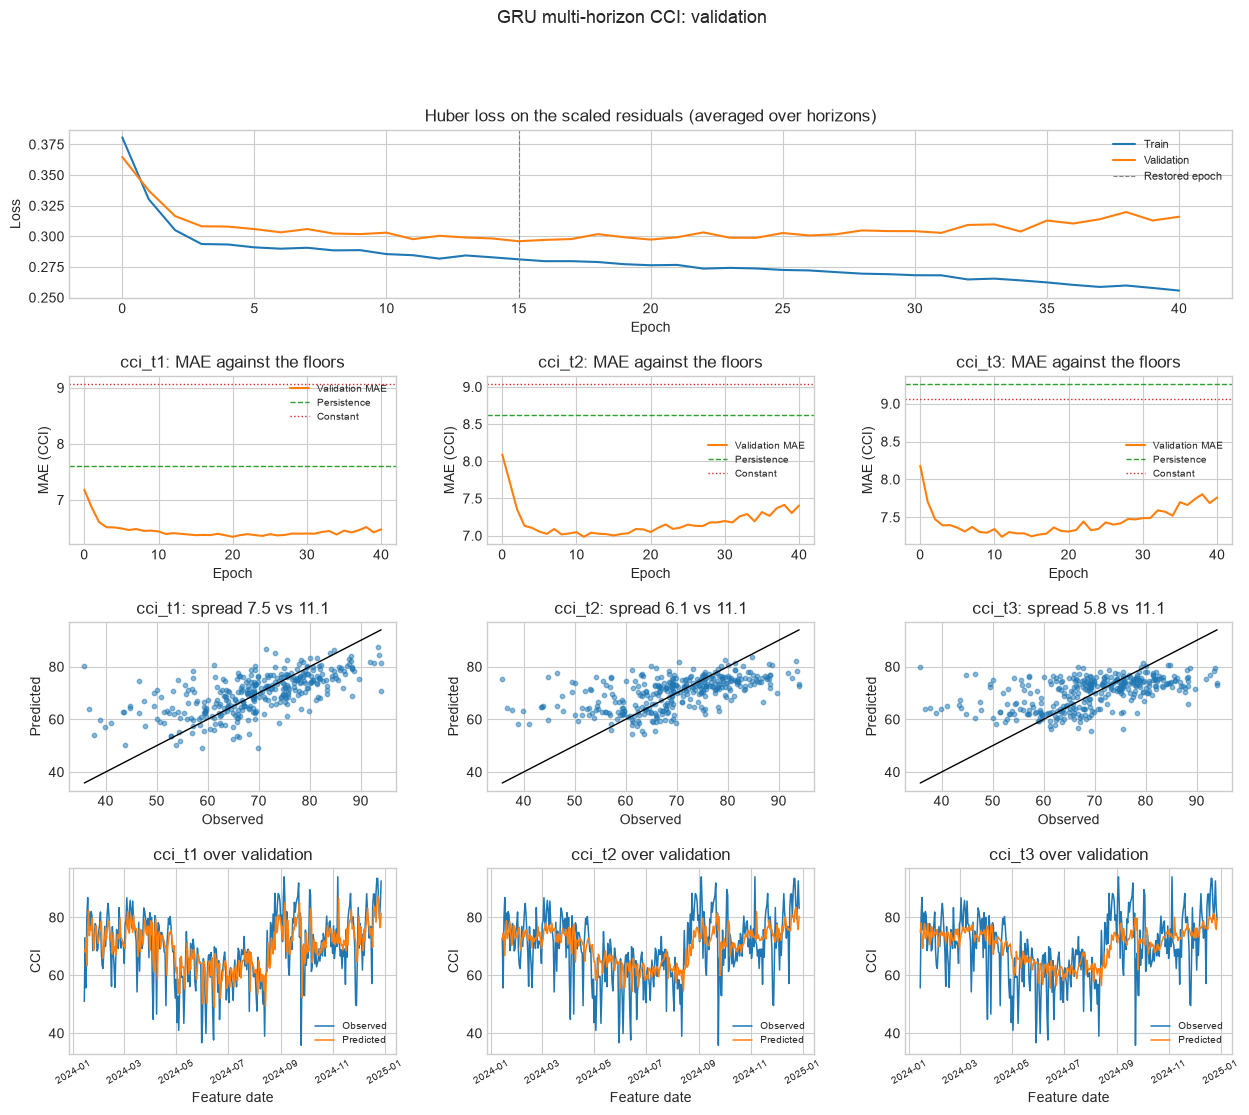

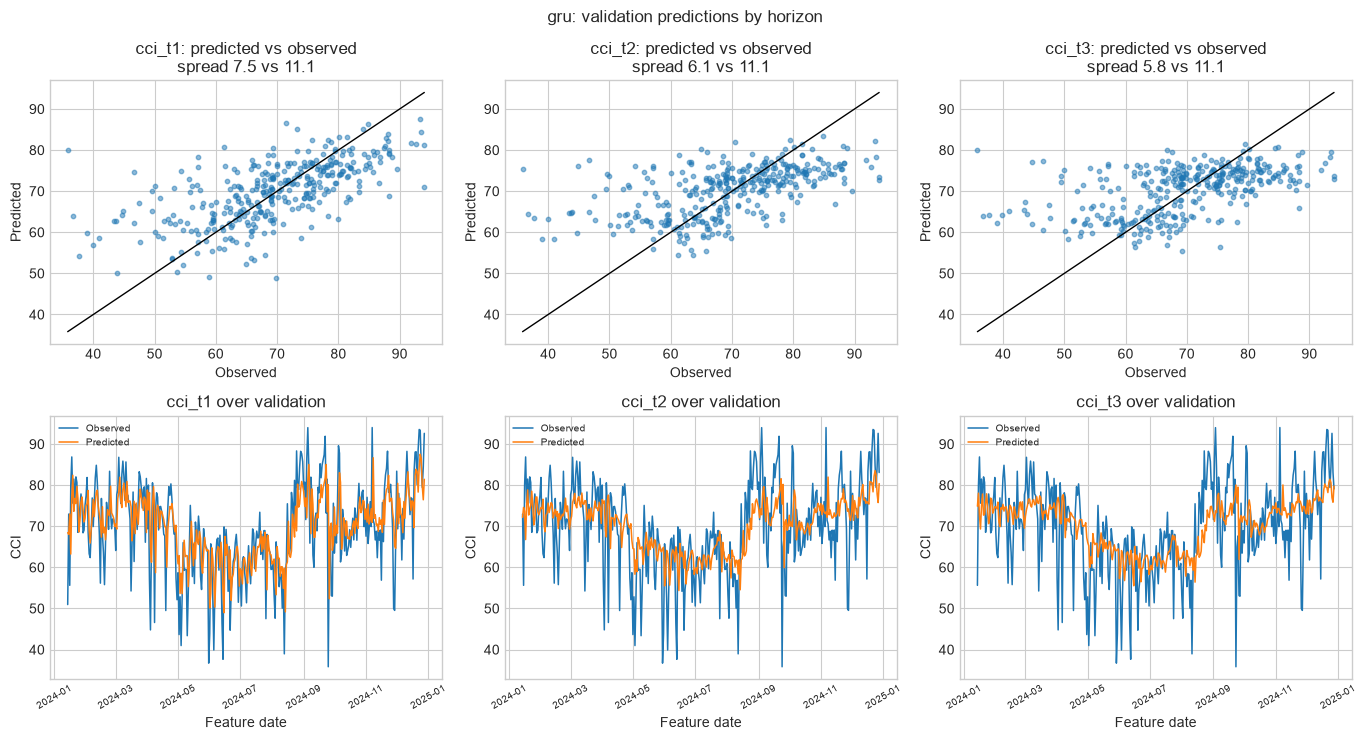

In [28]:
val_true = predictions["val"]["y_true"]
val_pred = predictions["val"]["y_pred"]
val_dates = predictions["val"]["dates"]

comparison = pd.DataFrame({"feature_date": val_dates})
for index, target in enumerate(TARGET_COLUMNS):
    comparison[f"{target}_actual"] = val_true[:, index]
    comparison[f"{target}_predicted"] = val_pred[:, index]
comparison["persistence"] = predictions["val"]["y_persist"]
print("Validation actual vs predicted CCI, all horizons (first and last three rows):")
display(pd.concat([comparison.head(3), comparison.tail(3)]))

n_horizons = len(TARGET_COLUMNS)
fig = plt.figure(figsize=(5.0 * n_horizons, 12))
grid = fig.add_gridspec(4, n_horizons, height_ratios=[1, 1, 1, 1.1], hspace=0.45, wspace=0.28)

loss_axis = fig.add_subplot(grid[0, :])
loss_axis.plot(curves["train_loss"], label="Train")
loss_axis.plot(curves["val_loss"], label="Validation")
loss_axis.axvline(best_epoch - 1, color="grey", ls="--", lw=0.8, label="Restored epoch")
loss_axis.set(title="Huber loss on the scaled residuals (averaged over horizons)",
              xlabel="Epoch", ylabel="Loss")
loss_axis.legend(fontsize=8)

for index, target in enumerate(TARGET_COLUMNS):
    mae_axis = fig.add_subplot(grid[1, index])
    mae_axis.plot(curves[f"val_mae_{target}"], color="tab:orange", label="Validation MAE")
    mae_axis.axhline(floors.loc[target, "persistence_floor_mae"], color="tab:green", ls="--",
                     lw=1, label="Persistence")
    mae_axis.axhline(floors.loc[target, "collapse_floor_mae"], color="tab:red", ls=":", lw=1,
                     label="Constant")
    mae_axis.set(title=f"{target}: MAE against the floors", xlabel="Epoch", ylabel="MAE (CCI)")
    mae_axis.legend(fontsize=7)

    scatter_axis = fig.add_subplot(grid[2, index])
    observed, predicted = val_true[:, index], val_pred[:, index]
    scatter_axis.scatter(observed, predicted, s=10, alpha=0.5)
    limits = [min(observed.min(), predicted.min()), max(observed.max(), predicted.max())]
    scatter_axis.plot(limits, limits, color="black", lw=1)
    scatter_axis.set(title=f"{target}: spread {np.std(predicted):.1f} vs "
                           f"{np.std(observed):.1f}",
                     xlabel="Observed", ylabel="Predicted")

for index, target in enumerate(TARGET_COLUMNS):
    series_axis = fig.add_subplot(grid[3, index])
    observed, predicted = val_true[:, index], val_pred[:, index]
    series_axis.plot(val_dates, observed, lw=1.1, label="Observed")
    series_axis.plot(val_dates, predicted, lw=1.1, label="Predicted")
    series_axis.set(title=f"{target} over validation", xlabel="Feature date", ylabel="CCI")
    series_axis.tick_params(axis="x", labelrotation=30, labelsize=7)
    series_axis.legend(fontsize=7)

fig.suptitle(f"{ARCHITECTURE} multi-horizon CCI: validation", fontsize=13)
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, n_horizons, figsize=(4.6 * n_horizons, 7.5))
for column, target in enumerate(TARGET_COLUMNS):
    observed, predicted = val_true[:, column], val_pred[:, column]
    scatter_axis = axes[0, column]
    scatter_axis.scatter(observed, predicted, s=10, alpha=0.5)
    limits = [min(observed.min(), predicted.min()), max(observed.max(), predicted.max())]
    scatter_axis.plot(limits, limits, color="black", lw=1)
    scatter_axis.set(
        title=(f"{target}: predicted vs observed\n"
               f"spread {np.std(predicted):.1f} vs {np.std(observed):.1f}"),
        xlabel="Observed",
        ylabel="Predicted",
    )
    series_axis = axes[1, column]
    series_axis.plot(val_dates, observed, lw=1.1, label="Observed")
    series_axis.plot(val_dates, predicted, lw=1.1, label="Predicted")
    series_axis.set(title=f"{target} over validation", xlabel="Feature date", ylabel="CCI")
    series_axis.tick_params(axis="x", labelrotation=30, labelsize=7)
    series_axis.legend(fontsize=7)
fig.suptitle(f"{MODEL_LABEL}: validation predictions by horizon", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-validation.png", dpi=150, bbox_inches="tight")
plt.show()


### Verdict

The check below states plainly, per horizon, whether the model is worth keeping. Three outcomes
are possible and all are legitimate results to report:

- **collapsed** — prediction spread near zero, so the model is emitting a constant. Do not report
  the result; find the cause first;
- **no improvement** — the model runs but adds nothing over carrying today's value forward. At
  *t*+3 this is a plausible finding and argues for deploying a tree model or persistence;
- **beats persistence** — the sequence model found signal persistence misses, and the margin is
  the number to report.


In [29]:
verdicts = {}
for index, target in enumerate(TARGET_COLUMNS):
    model_metrics = metrics_table.loc[("val", target, MODEL_LABEL)]
    persistence_mae = metrics_table.loc[("val", target, "persistence"), "mae"]
    spread_ratio = model_metrics["pred_std"] / np.std(val_true[:, index])
    margin = persistence_mae - model_metrics["mae"]

    if spread_ratio < 0.10:
        verdict = "COLLAPSED - near-constant output; do not report"
    elif margin <= 0:
        verdict = f"NO IMPROVEMENT - persistence better by {abs(margin):.3f} MAE"
    else:
        verdict = f"BEATS PERSISTENCE by {margin:.3f} MAE ({margin / persistence_mae:.1%})"
    verdicts[target] = verdict
    print(f"{target}: MAE {model_metrics['mae']:.3f} vs persistence {persistence_mae:.3f} | "
          f"spread {spread_ratio:.0%} of observed")
    print(f"          {verdict}\n")

print("Test split was not used.")


cci_t1: MAE 6.371 vs persistence 7.603 | spread 68% of observed
          BEATS PERSISTENCE by 1.232 MAE (16.2%)

cci_t2: MAE 7.003 vs persistence 8.624 | spread 55% of observed
          BEATS PERSISTENCE by 1.622 MAE (18.8%)

cci_t3: MAE 7.249 vs persistence 9.265 | spread 53% of observed
          BEATS PERSISTENCE by 2.016 MAE (21.8%)

Test split was not used.


## 7. Saved artefacts

One model file covers all three horizons, since they share an encoder. **Both scalers are
saved**, and any consumer must apply the input scaler to the sequence, then invert both the
target scaler and the residual framing to recover CCI values. The metadata records the inversion
explicitly so the step cannot be missed, and records the sequence feature order, which the API
must reproduce exactly — the network receives an unnamed tensor and will silently produce wrong
answers if the channels are permuted.

The 2025 test split remains unused.


In [30]:
artefact = {
    "experiment": EXPERIMENT,
    "student_id": "25945320",
    "architecture": ARCHITECTURE,
    "target": "Climate Comfort Index",
    "target_columns": TARGET_COLUMNS,
    "horizons_days": HORIZONS,
    "prediction_type": "regression",
    "learning_target": "cci_th - cci, standardised per horizon",
    "inversion": "cci_th = target_scaler.inverse_transform(output) + cci_at_t",
    "sequence_features": SEQUENCE_FEATURES,
    "sequence_feature_order_is_significant": True,
    "lookback_days": LOOKBACK,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "loss": "SmoothL1",
    "min_epochs": MIN_EPOCHS,
    "patience": PATIENCE,
    "best_epoch": best_epoch,
    "n_windows": {name: int(len(part["y_cci"])) for name, part in prepared.items()},
    "validation_metrics": {
        target: metrics_table.loc[("val", target, MODEL_LABEL)].drop("observed_std").to_dict()
        for target in TARGET_COLUMNS
    },
    "baseline_metrics": {
        target: {
            baseline: metrics_table.loc[("val", target, baseline)].drop("observed_std").to_dict()
            for baseline in ("persistence", "constant")
        }
        for target in TARGET_COLUMNS
    },
    "verdicts": verdicts,
    "split_boundaries": METADATA["split_boundaries"],
    "embargo_days": METADATA["embargo_days"],
    "evaluated_on": ["train", "val"],
    "held_out": ["test"],
}

model_path = MODEL_DIR / f"{EXPERIMENT}.pt"
input_scaler_path = MODEL_DIR / f"{EXPERIMENT}_input_scaler.joblib"
target_scaler_path = MODEL_DIR / f"{EXPERIMENT}_target_scaler.joblib"
metrics_path = MODEL_DIR / f"{EXPERIMENT}_metadata.json"

torch.save(
    {
        "state_dict": model.state_dict(),
        "architecture": ARCHITECTURE,
        "n_features": len(SEQUENCE_FEATURES),
        "hidden_size": HIDDEN_SIZE,
        "dropout": DROPOUT,
        "n_horizons": len(HORIZONS),
        "sequence_features": SEQUENCE_FEATURES,
        "lookback": LOOKBACK,
        "target_columns": TARGET_COLUMNS,
        "predicts_residual_against": PERSISTENCE_COLUMN,
    },
    model_path,
)
joblib.dump(input_scaler, input_scaler_path)
joblib.dump(target_scaler, target_scaler_path)
metrics_path.write_text(json.dumps(artefact, indent=2))

for label, path in (("model", model_path), ("input scaler", input_scaler_path),
                    ("target scaler", target_scaler_path), ("metadata", metrics_path)):
    print(f"Saved {label:14} {path.relative_to(PROJECT_ROOT)}")
print(f"Saved {'figure':14} "
      f"{(FIGURE_DIR / f'{EXPERIMENT}-evaluation.png').relative_to(PROJECT_ROOT)}")
print(f"Saved {'figure':14} "
      f"{(FIGURE_DIR / f'{EXPERIMENT}-validation.png').relative_to(PROJECT_ROOT)}")
print("\nTest split was not used in this notebook.")


Saved model          models/comfort_climate/cci_gru_multihorizon.pt
Saved input scaler   models/comfort_climate/cci_gru_multihorizon_input_scaler.joblib
Saved target scaler  models/comfort_climate/cci_gru_multihorizon_target_scaler.joblib
Saved metadata       models/comfort_climate/cci_gru_multihorizon_metadata.json
Saved figure         reports/figures/comfort_climate/cci_gru_multihorizon-evaluation.png
Saved figure         reports/figures/comfort_climate/cci_gru_multihorizon-validation.png

Test split was not used in this notebook.


## 8. Conclusions

Points to carry into the report:

- **Per-horizon verdicts.** Section 6 gives a separate judgement for each of *t*+1, *t*+2 and
  *t*+3. Report them separately rather than averaged; a model that helps at *t*+1 and not at
  *t*+3 is a meaningful finding about predictability, not a mixed result to be smoothed over.
- **Dispersion.** If `pred_std` sits well below `observed_std`, the network is hedging toward the
  mean because the signal is weak. Quote the ratio and explain it — it is the loss-minimising
  behaviour, and it limits operational usefulness for flagging poor-weather days.
- **Shared encoder versus separate models.** This notebook shares one encoder across horizons
  while the tree notebooks fit a separate model per horizon. If the recurrent models degrade less
  across horizons than the trees do, the shared representation is helping; if they degrade more,
  the encoder is being pulled between competing objectives.
- **Sample size.** {n_parameters} parameters against roughly 2,900 training windows is a
  demanding ratio. Losing to a tree ensemble here is an expected outcome, and reporting it with
  this explanation is stronger analysis than omitting the experiment.

The test split has not been touched. Use it once, after a single model has been chosen on
validation performance across all experiment notebooks.
